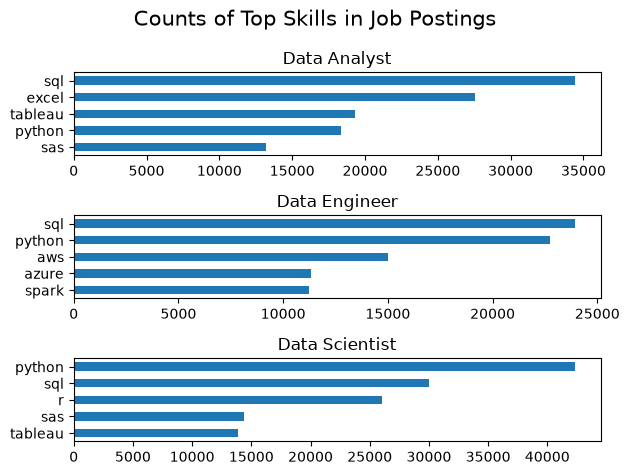

In [36]:
import pandas as pd
import ast
import matplotlib.pyplot as plt
from adjustText import adjust_text
from datasets import load_dataset
dataset=load_dataset('lukebarousse/data_jobs')
df=dataset['train'].to_pandas()
df['job_skills'] = df['job_skills'].apply(
    lambda x: ast.literal_eval(x) if pd.notna(x) and isinstance(x, str) else x
)

df_US= df[df['job_country']== 'United States']
df_skills=df_US.explode('job_skills')
df_skills[['job_title', 'job_skills']]
df_skills_count=df_skills.groupby(['job_skills', 'job_title_short']).size()
df_skills_count=df_skills_count.reset_index(name='skill_count')
df_skills_count.sort_values(by='skill_count', ascending=False,inplace=True)
df_skills_count

job_titles=['Data Analyst', 'Data Engineer', 'Data Scientist']
#job_titles=df_skills_count['job_title_short'].unique().tolist()
#job_titles=sorted(job_titles[:3])
job_titles

fig, ax=plt.subplots(len(job_titles),1)
for i,job_title in enumerate(job_titles):
    df_plot=df_skills_count[df_skills_count['job_title_short']==job_title].head(5)
    df_plot.plot(kind='barh', x= 'job_skills', y='skill_count', ax=ax[i],title=job_title)
    ax[i].invert_yaxis()
    ax[i].set_ylabel('')
    ax[i].legend().set_visible(False)

fig.suptitle('Counts of Top Skills in Job Postings', fontsize=15)
plt.tight_layout()
plt.show()




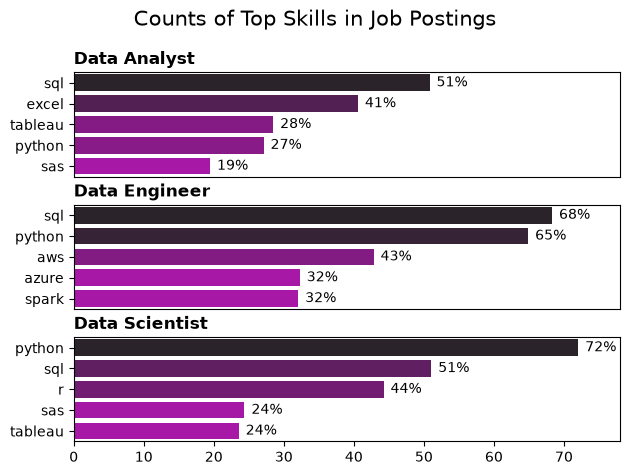

In [2]:
import pandas as pd
import ast
import matplotlib.pyplot as plt
from adjustText import adjust_text
from datasets import load_dataset
import seaborn as sns
dataset=load_dataset("lukebarousse/data_jobs")
df=dataset['train'].to_pandas()
df['job_skills'] = df['job_skills'].apply(
    lambda x: ast.literal_eval(x) if pd.notna(x) and isinstance(x, str) else x
)

df_US= df[df['job_country']== 'United States']
df_skills=df_US.explode('job_skills')
df_skills[['job_title', 'job_skills']]
df_skills_count=df_skills.groupby(['job_skills', 'job_title_short']).size()
df_skills_count=df_skills_count.reset_index(name='skill_count')
df_skills_count.sort_values(by='skill_count', ascending=False,inplace=True)
df_skills_count

job_titles=['Data Analyst', 'Data Engineer', 'Data Scientist']
job_titles
df_job_title_count=df_US['job_title_short'].value_counts().reset_index(name='jobs_total')
df_job_title_count

df_skills_perc=pd.merge(df_skills_count,df_job_title_count,how='left', on ='job_title_short')
df_skills_perc['skill_percent']=100 * df_skills_perc['skill_count'] / df_skills_perc['jobs_total']
df_skills_perc 

fig, ax=plt.subplots(len(job_titles),1)
for i,job_title in enumerate(job_titles):
    df_plot=df_skills_perc[df_skills_perc['job_title_short']==job_title].head(5)
    ax[i].set_title(job_title, fontsize=12, fontweight="bold", loc="left")
     #df_plot.plot(kind='barh', x= 'job_skills', y='skill_percent', ax=ax[i],title=job_title)
    sns.barplot(data=df_plot, x='skill_percent', y='job_skills', ax=ax[i], hue='skill_count', palette='dark:m_r')
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].get_legend().remove()
    #ax[i].legend().set_visible(False)
    ax[i].set_xlim(0,78)

    for n,v in enumerate(df_plot['skill_percent']):
        ax[i].text(v+1 ,n ,f'{v:.0f}%',va='center')

    if i !=len(job_titles) - 1:
        ax[i].set_xticks([])

#fig.suptitle('Counts of Top Skills in Job Postings', fontsize=15)

fig.suptitle(
    "Counts of Top Skills in Job Postings",
    fontsize=15,
)
plt.tight_layout(h_pad=0.5)
plt.show()

In [39]:
df_job_title_count=df_US['job_title_short'].value_counts().reset_index(name='jobs_total')
df_job_title_count

,job_title_short,jobs_total
0,Data Analyst,67816
1,Data Scientist,58830
2,Data Engineer,35080
3,Senior Data Scientist,12946
4,Senior Data Analyst,11791
5,Senior Data Engineer,9289
6,Business Analyst,7382
7,Software Engineer,1814
8,Machine Learning Engineer,921
9,Cloud Engineer,423


In [43]:
df_skills_perc=pd.merge(df_skills_count,df_job_title_count,how='left', on ='job_title_short')
df_skills_perc['skill_percent']=100 * df_skills_perc['skill_count'] / df_skills_perc['jobs_total']
df_skills_perc

,job_skills,job_title_short,skill_count,jobs_total,skill_percent
0,python,Data Scientist,42379,58830,72.036376
1,sql,Data Analyst,34452,67816,50.802171
2,sql,Data Scientist,30034,58830,51.052184
3,excel,Data Analyst,27519,67816,40.578919
4,r,Data Scientist,26022,58830,44.232534
...,...,...,...,...,...
1865,vue.js,Business Analyst,1,7382,0.013546
1866,arch,Business Analyst,1,7382,0.013546
1867,asana,Machine Learning Engineer,1,921,0.108578
1868,no-sql,Machine Learning Engineer,1,921,0.108578
